# 🏋️ Limpieza de datos y análisis exploratorio — Clientes de un gimnasio

**Autor:** Chris Nelson · **Contexto:** Talendig · Mes 4 · Semana 2 · Data Science para IA

Registro de clientes de un gimnasio con tres sedes en Santo Domingo (**Naco, Piantini y Gazcue**). Como cualquier dataset real, llega con información incompleta, registros repetidos por error y una columna numérica que en realidad es una categoría. El objetivo es detectar cada problema, resolverlo y **justificar cada decisión**.

## Contenido
1. [Configuración e imports](#1.-Configuración-e-imports)
2. [Carga y exploración inicial](#2.-Carga-y-exploración-inicial)
3. [Diagnóstico de valores nulos](#3.-Diagnóstico-de-valores-nulos)
4. [Eliminación de duplicados](#4.-Eliminación-de-duplicados)
5. [Tratamiento de nulos](#5.-Tratamiento-de-nulos)
6. [Corrección de tipos de datos](#6.-Corrección-de-tipos-de-datos)
7. [Media vs. mediana de la edad](#7.-Media-vs.-mediana-de-la-edad)
8. [Validación final y exportación](#8.-Validación-final-y-exportación)
9. [Reflexión final](#9.-Reflexión-final)
10. [Conclusiones y limitaciones](#10.-Conclusiones-y-limitaciones)

## Diccionario de datos

| Columna | Significado |
|---|---|
| `ClienteID` | Identificador único de cada cliente |
| `Nombre` | Nombre completo del cliente |
| `Edad` | Edad en años |
| `Plan` | Tipo de membresía: 1 = Básico, 2 = Premium, 3 = VIP |
| `Sucursal` | Sede donde se inscribió: Naco, Piantini o Gazcue |
| `DiasAsistidosMes` | Días que asistió al gimnasio en el último mes |
| `Email` | Correo electrónico (el gimnasio empezó a pedirlo hace poco) |

## 1. Configuración e imports

- **pandas** para manipular los datos.
- **matplotlib** para las visualizaciones.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Carga y exploración inicial

Antes de modificar nada, miramos qué tenemos: tamaño, primeras filas y tipos de datos. Guardamos una copia intacta (`df_original`) para poder comparar después.

> 📁 La ruta es `../data/...` porque este notebook vive en `notebooks/` y los datos en `data/`.

In [2]:
df = pd.read_csv("../data/clientes_gimnasio.csv")
df_original = df.copy()  # copia sin modificar

print("Forma del dataset:", df.shape)
df.head()

Forma del dataset: (63, 7)


,ClienteID,Nombre,Edad,Plan,Sucursal,DiasAsistidosMes,Email
0,56,Carlos Fernandez,64.0,1,Naco,4,carlos56@gmail.com
1,17,Juan Reyes,47.0,3,Naco,29,NaN
2,8,Yolanda Castillo,52.0,3,Naco,30,NaN
3,25,Francisco Garcia,43.0,1,Naco,25,NaN
4,7,Patricia Rodriguez,NaN,2,Naco,23,NaN


In [3]:
# Tipo de dato de cada columna
df.dtypes

ClienteID             int64
Nombre                  str
Edad                float64
Plan                  int64
Sucursal                str
DiasAsistidosMes      int64
Email                   str
dtype: object

## 3. Diagnóstico de valores nulos

Contamos cuántos nulos hay por columna y qué porcentaje representan, y lo visualizamos.

In [4]:
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().sum() / len(df) * 100).round(2),
})
nulos[nulos["nulos"] > 0].sort_values("porcentaje", ascending=False)

,nulos,porcentaje
Email,47,74.60
Edad,11,17.46
Sucursal,2,3.17


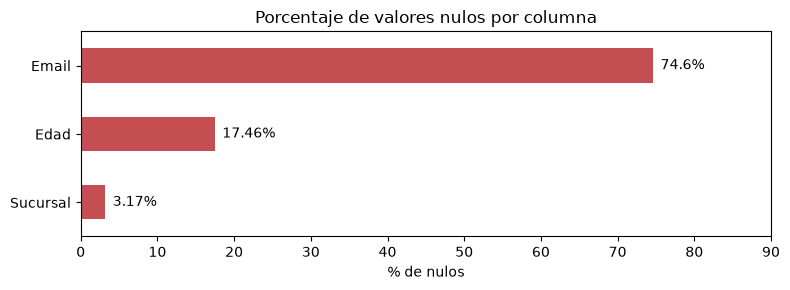

In [5]:
nulos_pct = nulos.loc[nulos["nulos"] > 0, "porcentaje"].sort_values()

ax = nulos_pct.plot.barh(color="#C44E52", figsize=(8, 3))
ax.set_title("Porcentaje de valores nulos por columna")
ax.set_xlabel("% de nulos")
for i, v in enumerate(nulos_pct):
    ax.text(v + 1, i, f"{v}%", va="center")
ax.set_xlim(0, 90)
plt.tight_layout()
plt.show()

Tres columnas tienen nulos, y **no todos tienen el mismo origen**:

| Columna | Nulos | Decisión | Por qué |
|---|---|---|---|
| `Edad` | 17.46 % | Rellenar con la **mediana** | Es numérica y puede tener valores extremos (clientes de 90+ años). La mediana no se deja arrastrar por ellos. |
| `Sucursal` | 3.17 % | Rellenar con la **moda** | Es categórica y solo faltan 2 filas. El valor más frecuente es la opción menos distorsionante. |
| `Email` | 74.60 % | **Eliminar la columna** | No se puede adivinar un correo que nunca se registró. Además, el gimnasio empezó a pedirlo hace poco: faltan por *cuándo* se recolectó el dato, no por errores de captura. |

> 💡 Esta decisión es específica para este ejercicio. Si el negocio necesitara contactar a los clientes por correo, conservaríamos la columna.

## 4. Eliminación de duplicados

Hay clientes registrados dos veces por error. Los eliminamos **antes** de imputar nulos: así evitamos que dos filas distintas se vuelvan idénticas por culpa de un relleno y se borren por equivocación.

Primero las visualizamos:

In [6]:
duplicados = df[df.duplicated(keep=False)].sort_values("ClienteID")
print(f"Filas involucradas en duplicados: {len(duplicados)}")
duplicados[["ClienteID", "Nombre", "Edad", "Plan", "Sucursal", "DiasAsistidosMes"]]

Filas involucradas en duplicados: 6


,ClienteID,Nombre,Edad,Plan,Sucursal,DiasAsistidosMes
38,21,Gabriela Mejia,17.0,1,Gazcue,11
50,21,Gabriela Mejia,17.0,1,Gazcue,11
5,32,Ricardo Pena,43.0,1,Naco,24
40,32,Ricardo Pena,43.0,1,Naco,24
52,60,Fernanda Cruz,17.0,3,Naco,13
57,60,Fernanda Cruz,17.0,3,Naco,13


In [7]:
print("Filas antes:", len(df))
df = df.drop_duplicates()
print("Filas después:", len(df))
print("Filas eliminadas:", len(df_original) - len(df))

# ClienteID es un identificador único: no debe repetirse
assert df["ClienteID"].is_unique

Filas antes: 63
Filas después: 60
Filas eliminadas: 3


## 5. Tratamiento de nulos

Aplicamos las tres decisiones de la sección 3.

In [8]:
# Edad → mediana (robusta a los valores extremos)
mediana_edad = df["Edad"].median()
df["Edad"] = df["Edad"].fillna(mediana_edad)

# Sucursal → moda (la sede más frecuente)
moda_sucursal = df["Sucursal"].mode()[0]
df["Sucursal"] = df["Sucursal"].fillna(moda_sucursal)

# Email → se elimina la columna completa
df = df.drop(columns=["Email"])

print("Mediana usada para Edad:", mediana_edad)
print("Moda usada para Sucursal:", moda_sucursal)
print("Nulos restantes:", df.isnull().sum().sum())
print("Forma del dataset:", df.shape)

Mediana usada para Edad: 47.0
Moda usada para Sucursal: Naco
Nulos restantes: 0
Forma del dataset: (60, 6)


## 6. Corrección de tipos de datos

`Plan` está guardada como entero, pero sus valores (1, 2, 3) son **etiquetas**, no cantidades: un plan VIP no es "tres veces" un plan Básico. Si la dejamos numérica, pandas nos dejaría calcular un "promedio de plan" sin avisar que no tiene sentido.

Equivalencias: `1 = Básico`, `2 = Premium`, `3 = VIP`.

In [9]:
df["Plan"] = df["Plan"].astype("category")
df.dtypes

ClienteID              int64
Nombre                   str
Edad                 float64
Plan                category
Sucursal                 str
DiasAsistidosMes       int64
dtype: object

## 7. Media vs. mediana de la edad

Entre los clientes hay edades de 90, 93 y 96 años. ¿Cuánto afectan a cada medida?

Calculamos la comparación de dos formas:
- **Dataset limpio:** incluye las 11 edades que rellenamos con la mediana.
- **Solo edades reales:** sin las imputadas, para ver el efecto sin que el relleno lo suavice.

> ⚠️ Los clientes mayores de 85 **no se eliminan** del dataset: una edad alta no es automáticamente un error. Es solo un análisis de sensibilidad.

In [10]:
def resumen(edades):
    """Media y mediana, con todos los clientes y sin los mayores de 85."""
    sin_mayores = edades[edades <= 85]
    return {
        "Media (todos)": round(edades.mean(), 2),
        "Media (<= 85)": round(sin_mayores.mean(), 2),
        "Mediana (todos)": edades.median(),
        "Mediana (<= 85)": sin_mayores.median(),
    }

# Edades reales: las que NO fueron rellenadas (se detectan en el dataset sin duplicados)
edades_reales = df_original.drop_duplicates()["Edad"].dropna()

comparacion = pd.DataFrame({
    "Dataset limpio (con imputadas)": resumen(df["Edad"]),
    "Solo edades reales": resumen(edades_reales),
}).T
print("Clientes mayores de 85 años:", int((df["Edad"] > 85).sum()))
comparacion

Clientes mayores de 85 años: 3


,Media (todos),Media (<= 85),Mediana (todos),Mediana (<= 85)
Dataset limpio (con imputadas),46.50,44.05,47.0,47.0
Solo edades reales,46.39,43.35,47.0,47.0


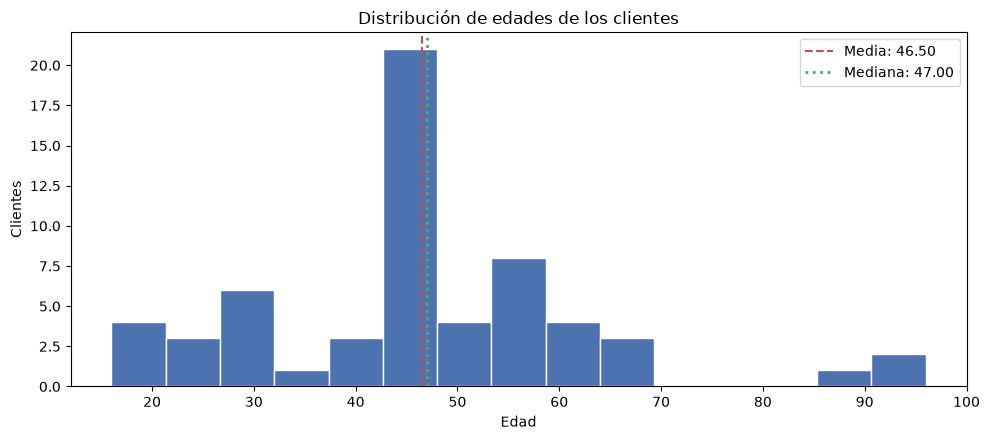

In [11]:
media = df["Edad"].mean()
mediana = df["Edad"].median()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(df["Edad"], bins=15, color="#4C72B0", edgecolor="white")
ax.axvline(media, color="#C44E52", linestyle="--", label=f"Media: {media:.2f}")
ax.axvline(mediana, color="#55A868", linestyle=":", linewidth=2, label=f"Mediana: {mediana:.2f}")
ax.set_title("Distribución de edades de los clientes")
ax.set_xlabel("Edad")
ax.set_ylabel("Clientes")
ax.legend()
plt.tight_layout()
plt.show()

📌 **Resultado:** al excluir a los mayores de 85, la **media baja** (de 46.50 a 44.05 en el dataset limpio, y de 46.39 a 43.35 con edades reales), mientras que la **mediana no se mueve** (47 en todos los casos).

Tiene sentido: la media suma todos los valores, así que tres edades de 90+ la arrastran hacia arriba. La mediana solo mira el valor central, y quitar unos pocos extremos no cambia quién queda en el medio.

Además, el efecto es **menor en el dataset limpio** (−2.45) que con edades reales (−3.04). Es consecuencia de haber rellenado 11 edades con el mismo valor (47): amontonan datos en el centro y suavizan las diferencias. Es un recordatorio de que imputar con un valor constante cambia la forma de la distribución.

## 8. Validación final y exportación

Verificamos que el dataset cumple lo esperado y lo guardamos en `data/`.

In [12]:
assert df.shape == (60, 6)
assert df.isnull().sum().sum() == 0
assert df.duplicated().sum() == 0
assert str(df["Plan"].dtype) == "category"
print("Validación OK ✔")

print("\nForma final:", df.shape)
print("Nulos restantes:", df.isnull().sum().sum())
print("Duplicados restantes:", df.duplicated().sum())
df.head()

Validación OK ✔

Forma final: (60, 6)
Nulos restantes: 0
Duplicados restantes: 0


,ClienteID,Nombre,Edad,Plan,Sucursal,DiasAsistidosMes
0,56,Carlos Fernandez,64.0,1,Naco,4
1,17,Juan Reyes,47.0,3,Naco,29
2,8,Yolanda Castillo,52.0,3,Naco,30
3,25,Francisco Garcia,43.0,1,Naco,25
4,7,Patricia Rodriguez,47.0,2,Naco,23


In [13]:
df.to_csv("../data/clientes_gimnasio_limpio.csv", index=False)
print("Archivo guardado: ../data/clientes_gimnasio_limpio.csv")

Archivo guardado: ../data/clientes_gimnasio_limpio.csv


## 9. Reflexión final

### 1. Media vs. mediana
Al excluir a los clientes mayores de 85 años, la **media** cambió (≈ 2.5 años menos) y la **mediana** no cambió. La media usa todos los valores, por eso los extremos la jalan; la mediana solo depende de la posición central. (Detalle en la sección 7.)

### 2. Dos columnas de texto, dos estrategias distintas
Aunque `Sucursal` y `Email` son de texto, el problema es distinto:

- **`Sucursal` (3.17 %)** faltan solo 2 filas y existe un valor "razonable" para rellenar (la sede más frecuente). Imputar cuesta poco y evita perder filas.
- **`Email` (74.60 %)** faltan casi tres de cada cuatro. Rellenar sería **inventar** datos, porque un correo no se puede deducir de otras columnas. Además, el vacío es estructural (el gimnasio empezó a pedirlo hace poco), así que no es ruido aleatorio sino un reflejo de cuándo se recolectó el dato.

En resumen: no importa solo el tipo de dato, también el **porcentaje de nulos** y **si existe una forma razonable de reconstruir el valor**.

### 3. Mirando hacia adelante: predecir cancelaciones
Antes de usar estos datos para predecir quién cancelará su membresía tomaría estas precauciones:

- **No hay variable objetivo.** Este dataset no dice quién canceló. Necesitaríamos un historial real de cancelaciones.
- **`DiasAsistidosMes` es una foto de un solo mes**, no una tendencia. Para detectar riesgo conviene ver cómo evoluciona la asistencia en el tiempo.
- **Los valores imputados no son reales.** 11 edades valen 47 y 2 sucursales valen "Naco" solo porque rellenamos así; el modelo trataría esos datos inventados como verdaderos.
- **Evitar fuga de datos (data leakage).** La mediana y la moda deben calcularse **solo con el conjunto de entrenamiento** y luego aplicarse al de prueba, no con todo el dataset.
- **Validar los casos extremos** (edades de 90+) con el negocio antes de decidir si son reales o errores.
- **Muestra pequeña** (60 clientes) y desbalanceada por sede: Naco concentra la mayoría.

## 10. Conclusiones y limitaciones

- Se partió de **63 filas y 7 columnas** y se terminó con **60 filas y 6 columnas**, sin nulos ni duplicados.
- `Edad` se imputó con la **mediana**, `Sucursal` con la **moda** y `Email` se **eliminó**, cada decisión según el significado y el porcentaje de nulos de la columna.
- Se eliminaron **3 filas duplicadas**; `ClienteID` quedó único.
- `Plan` pasó de `int64` a `category`.
- La mediana resultó más **robusta** que la media frente a los clientes de 90+ años.

**Limitaciones**
- Rellenar edades con la mediana no recupera la edad real de cada cliente y suaviza la distribución.
- Rellenar sucursales con la moda asume que esos clientes pertenecen a la sede más común.
- Eliminar `Email` deja el dataset sin esa información.
- `drop_duplicates()` solo detecta filas **exactamente** iguales; no detecta a la misma persona registrada con datos ligeramente distintos.
- Las edades mayores a 85 se usaron solo para comparar, no como regla de limpieza.

**Siguientes pasos:** analizar si la asistencia (`DiasAsistidosMes`) varía por plan o sede, y validar las edades extremas con el gimnasio.